# LLMy w praktyce – zajęcia 2
## Od słów do wektorów: embeddingi

## O czym są te zajęcia i dlaczego to ważne?

Na zajęciach 1 zamieniliśmy słowa na **numery** (indeksy): `"kot" → 17`, `"pies" → 18`.
Sieć neuronowa potrzebuje liczb, ale sam numer **nic nie mówi o znaczeniu**: z tego, że 17 i 18 są obok siebie,
nie wynika, że kot i pies są podobne. Potrzebujemy lepszej reprezentacji: **wektora liczb**, w którym słowa o podobnym
znaczeniu leżą blisko siebie. Taki wektor to **embedding** (zanurzenie).

To nie jest ciekawostka – to **pierwsza warstwa każdego LLM-a**. GPT-2 ma tablicę embeddingów o wymiarze
**50 257 × 768**: każdy token ze słownika ma swój wektor 768 liczb. Wszystko, co model „wie” o tokenie na wejściu,
jest zapisane w tym wektorze.

**Na dzisiejszych zajęciach:**
1. **one-hot** – najprostszy wektor dla słowa; zobaczymy, dlaczego nie wystarcza,
2. **Bag-of-Words** – wektor dla całego zdania; co tracimy,
3. **word2vec** – wektory, których model **uczy się sam**, przewidując sąsiednie słowa
   (to mały model językowy – bardzo podobna idea jak w GPT),
4. **gotowe wektory GloVe** – podobieństwa, „arytmetyka znaczeń” (`king − man + woman ≈ queen`), wizualizacja,
5. **ograniczenie**: jedno słowo = jeden wektor. To problem, który rozwiązuje mechanizm uwagi (zajęcia 7).

**Dlaczego to ważne?** Embeddingi to „język”, w którym LLM myśli o tokenach. Zrozumienie, *skąd* biorą się sensowne wektory
(z przewidywania kontekstu) i *czego im brakuje* (kontekstu zdania), prowadzi wprost do architektury GPT.

**Plan (ok. 90 min):**

| Część | Temat | Czas |
|---|---|---|
| 1–2 | One-hot, podobieństwo cosinusowe, Bag-of-Words | 20 min |
| 3 | word2vec: jak model uczy się wektorów | 25 min |
| 4–5 | Gotowe wektory GloVe, analogie, wizualizacja | 30 min |
| 6–7 | Ograniczenia i podsumowanie | 15 min |

Na końcu notatnika są **zadania domowe**.

> **Uwaga techniczna:** w części 3 i 4 pobieramy dane (ok. 30 MB i 130 MB). Uruchom komórkę instalacyjną na samym początku.

### Słownik pojęć
- **Wektor** – lista liczb, np. `[0.2, -1.3, 0.7]`. Można go traktować jak punkt (strzałkę) w przestrzeni.
- **Embedding (zanurzenie)** – wektor reprezentujący token. Słowa o podobnym znaczeniu mają podobne wektory.
- **Podobieństwo cosinusowe** – miara podobieństwa dwóch wektorów: cosinus kąta między nimi.
  $\cos(a, b) = \dfrac{a \cdot b}{\|a\|\,\|b\|}$. Wartość 1 – ten sam kierunek, 0 – prostopadłe (brak związku), −1 – przeciwne.
- **One-hot** – wektor z jedną jedynką (na pozycji słowa) i samymi zerami.
- **Bag-of-Words (BoW)** – wektor zdania: ile razy wystąpiło każde słowo ze słownika.
- **Okno kontekstu (window)** – ile słów w lewo i w prawo traktujemy jako „sąsiadów” słowa.
- **word2vec (skip-gram)** – metoda uczenia embeddingów przez przewidywanie sąsiednich słów.
- **PCA** – metoda zmniejszania liczby wymiarów (np. ze 100 do 2), żeby dało się narysować wektory.

In [1]:
!pip install -q gensim

In [2]:
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

def cosine(a, b, eps=1e-12):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + eps))

print("Imports OK")

Imports OK


## 1. One-hot: każde słowo osobno

**One-hot** to najprostszy sposób, żeby zamienić słowo na wektor: wektor ma długość równą rozmiarowi słownika,
a jedynka stoi na pozycji danego słowa.

In [3]:
vocab = ["ala", "ma", "kota", "pies"]          # słownik
one_hot = np.eye(len(vocab), dtype=int)       # macierz jednostkowa: każdy wiersz to jedno słowo

for word, vec in zip(vocab, one_hot):
    print(f"{word:>5} -> {vec}")

  ala -> [1 0 0 0]
   ma -> [0 1 0 0]
 kota -> [0 0 1 0]
 pies -> [0 0 0 1]


### Zadanie 1
1. Utwórz wektory one-hot dla słownika `["kot", "pies", "kość", "mleko"]` i policz podobieństwo cosinusowe **każdej pary** słów (macierz 4×4).
2. Czy one-hot modeluje podobieństwo znaczeń? Czy „kot” jest bliżej „psa” niż „mleka”?
3. Słownik GPT-2 ma 50 257 tokenów. Jak długi byłby wektor one-hot jednego tokenu? Ile pamięci zajęłoby zakodowanie tekstu
   o długości 1000 tokenów, jeśli każda liczba zajmuje 4 bajty (`float32`)? Porównaj z embeddingiem GPT-2 (768 liczb na token).

In [4]:
# TODO
vocab_task1 = ["kot", "pies", "kość", "mleko"]
one_hot_task1 = np.eye(len(vocab_task1), dtype=int)
M = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        M[i, j] = cosine(one_hot_task1[i], one_hot_task1[j])
print(M)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


**Odpowiedzi:**
2. Nie. Reprezentacja one-hot traktuje każde słowo jako niezależny, ortogonalny wymiar — wszystkie różne słowa są od siebie tak samo „dalekie” (podobieństwo cosinusowe wynosi 0.0 dla każdej pary różnych słów).
3. Długość wektora one-hot jednego tokenu: 50 257 liczb. Pamięć dla tekstu o długości 1000 tokenów (one-hot, float32):1000 * 50257 * 4B = 201MB. Porównanie z embeddingiem GPT-2: 1000 * 768 * 4B = 3,07MB Wniosek: reprezentacja one-hot dla 1000 tokenów zajmuje około 65,4 razy więcej pamięci
*(miejsce na Twoje odpowiedzi)*

## 2. Bag-of-Words: wektor dla całego zdania

**Bag-of-Words (BoW, „worek słów”)** opisuje zdanie wektorem **liczby wystąpień** każdego słowa ze słownika.
Kolejność słów jest ignorowana – wrzucamy je do „worka”.

In [5]:
docs = [
    "ala ma kota",
    "pies ma kość",
    "kot pije mleko",
    "kot ma mleko",
]
vocab_bow = sorted(set(" ".join(docs).split()))
print("Słownik:", vocab_bow)

def bow_vector(text):
    counts = Counter(text.split())
    return np.array([counts[w] for w in vocab_bow])

for doc in docs:
    print(f"{doc:<15} -> {bow_vector(doc)}")

Słownik: ['ala', 'kot', 'kota', 'kość', 'ma', 'mleko', 'pies', 'pije']
ala ma kota     -> [1 0 1 0 1 0 0 0]
pies ma kość    -> [0 0 0 1 1 0 1 0]
kot pije mleko  -> [0 1 0 0 0 1 0 1]
kot ma mleko    -> [0 1 0 0 1 1 0 0]


### Zadanie 2
1. Policz podobieństwo cosinusowe między wszystkimi parami zdań z `docs`. Które zdania są najbardziej podobne? Dlaczego?
2. Czy „ala ma kota” i „kot pije mleko” mają coś wspólnego według BoW? A według człowieka?
3. Sprawdź podobieństwo BoW zdań `"dog bites man"` i `"man bites dog"`. Co tracimy w reprezentacji BoW?
4. Co by się stało z podobieństwami, gdybyśmy dopisali do każdego zdania częste słowa funkcyjne, np. „i”, „a”, „że”?

In [6]:
# TODO
M = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        M[i, j] = cosine(bow_vector(docs[i]), bow_vector(docs[j]))
print(M)

s1 = "dog bites man"
s2 = "man bites dog"
vocab_box = sorted(set((s1 + " "+ s2).split()))
def sprawdz(sx):
    counts = Counter(sx.split())
    return np.array([counts[w] for w in vocab_box])
print(cosine(sprawdz(s1), sprawdz(s2)))

[[1.         0.33333333 0.         0.33333333]
 [0.33333333 1.         0.         0.33333333]
 [0.         0.         1.         0.66666667]
 [0.33333333 0.33333333 0.66666667 1.        ]]
0.9999999999996668


**Odpowiedzi:**
1. oprócz porównań z tymi samymi zdaniami najbardziej podobne są ala ma kota i kot ma ale gdyż mają 2 z 3 słów takie same.
2. według bow nie gdyż nie ma żadnego takiego samego wyrazu, a według człowieka tak gdyż oba zdania dotyczą kota.
3. tracimy sens wypowiedzi natomiast podobieństwo jest stuprocentowe
4. Słowa funkcyjne (tzw. stop words) występowałyby w każdym zdaniu, więc wektory wszystkich dokumentów zyskałyby wspólne niezerowe współrzędne i zaczęłyby „patrzeć w tę samą stronę”. Zatarłoby to różnice między zdaniami o zupełnie różnej tematyce
*(miejsce na Twoje odpowiedzi)*

## 3. word2vec: model sam uczy się wektorów

### 3.1 Idea: „poznasz słowo po jego towarzystwie”

Lingwista J.R. Firth (1957): *„You shall know a word by the company it keeps”*. Jeśli „kot” i „pies” pojawiają się w podobnych
kontekstach („… pije wodę”, „… śpi na …”, „… je karmę”), to prawdopodobnie znaczą coś podobnego.

**word2vec (wariant skip-gram)** zamienia tę obserwację w zadanie dla sieci neuronowej:
1. bierzemy słowo ze środka okna,
2. sieć ma przewidzieć jego **sąsiadów** (słowa w oknie po lewej i prawej),
3. jedyne, co sieć może zmieniać, to wektory słów (tablica embeddingów).

Żeby dobrze przewidywać sąsiadów, słowa z podobnymi sąsiadami **muszą** dostać podobne wektory. Embeddingi powstają „przy okazji” uczenia.

> **Most do LLM-ów:** word2vec to mały model językowy – przewiduje słowa z kontekstu. GPT przewiduje **następne** słowo
> i też ma na wejściu tablicę embeddingów, której uczy się dokładnie w ten sposób: przy okazji przewidywania tekstu.

Zobaczmy, jakie przykłady treningowe (pary *słowo → sąsiad*) powstają z jednego zdania:

In [7]:
def skipgram_pairs(sentence, window):
    pairs = []
    for i, center in enumerate(sentence):
        for j in range(max(0, i - window), min(len(sentence), i + window + 1)):
            if j != i:
                pairs.append((center, sentence[j]))
    return pairs

sentence = ["pies", "je", "kość", "w", "ogrodzie"]
for p in skipgram_pairs(sentence, window=1):
    print(p)

('pies', 'je')
('je', 'pies')
('je', 'kość')
('kość', 'je')
('kość', 'w')
('w', 'kość')
('w', 'ogrodzie')
('ogrodzie', 'w')


### Zadanie 3
1. Ile par treningowych powstaje dla tego zdania przy `window=1`, a ile przy `window=2`? Sprawdź kodem.
2. Mamy korpus: „kot pije mleko”, „pies pije wodę”, „kot je karmę”, „pies je kość”. Wypisz sąsiadów słowa „kot” i słowa „pies” (`window=1`).
   Które słowa powinny dostać podobne wektory? Dlaczego?

In [8]:
# TODO
for p in skipgram_pairs(sentence, window=2):
    print(p)

corpus = [
    "kot pije mleko",
    "pies pije wodę",
    "kot je karmę",
    "pies je kość",
]

print("\n")
for target in ["kot", "pies"]:
    neighbors = []
    for doc in corpus:
        tokens = doc.split()
        for center, ctx in skipgram_pairs(tokens, window=1):
            if center == target:
                neighbors.append(ctx)
    print(f"Sąsiedzi '{target}' (window=1): {neighbors}")

('pies', 'je')
('pies', 'kość')
('je', 'pies')
('je', 'kość')
('je', 'w')
('kość', 'pies')
('kość', 'je')
('kość', 'w')
('kość', 'ogrodzie')
('w', 'je')
('w', 'kość')
('w', 'ogrodzie')
('ogrodzie', 'kość')
('ogrodzie', 'w')


Sąsiedzi 'kot' (window=1): ['pije', 'je']
Sąsiedzi 'pies' (window=1): ['pije', 'je']


**Odpowiedzi:**
1. 8 jak window = 1 14 jak window = 2
2. kot oraz pies gdyż maja identyczne otoczenie sąsiadów, W Skip-gram słowa pojawiające się w tych samych kontekstach uczą się przewidywać tych samych sąsiadów, więc ich wektory stają się do siebie podobne (mają wysokie podobieństwo cosinusowe).
*(miejsce na Twoje odpowiedzi)*

### 3.2 Trenujemy word2vec na małym korpusie

Użyjemy biblioteki **gensim**. Najważniejsze parametry:
- `vector_size` – wymiar wektora (ile liczb opisuje słowo),
- `window` – szerokość okna kontekstu,
- `min_count` – pomijamy słowa rzadsze niż ta liczba,
- `sg=1` – wariant skip-gram (przewidujemy sąsiadów ze słowa),
- `epochs` – ile razy przechodzimy przez dane,
- `seed`, `workers=1` – powtarzalność wyników.

In [9]:
from gensim.models import Word2Vec

toy_corpus = [
    ["ala", "ma", "kota"], ["pies", "ma", "kość"], ["kot", "pije", "mleko"], ["pies", "je", "kość"],
    ["ala", "ma", "psa"], ["pies", "gryzie", "kość"], ["pies", "niesie", "kość"], ["pies", "lubi", "kość"],
    ["kot", "lubi", "mleko"], ["kot", "pije", "mleko", "rano"], ["kot", "je", "rybę"], ["pies", "je", "karmę"],
    ["kot", "je", "karmę"], ["pies", "pije", "wodę"], ["kot", "śpi", "na", "kanapie"], ["pies", "śpi", "na", "dywanie"],
]

toy_model = Word2Vec(toy_corpus, vector_size=10, window=2, min_count=1, sg=1, epochs=100, seed=0, workers=1)

print("Wektor 'pies':", np.round(toy_model.wv["pies"], 2))
print("Najbardziej podobne do 'pies':", toy_model.wv.most_similar("pies", topn=4))
print("sim(kot, pies) =", round(float(toy_model.wv.similarity("kot", "pies")), 2))

Wektor 'pies': [ 0.07  0.03  0.   -0.05 -0.03 -0.09 -0.09 -0.1  -0.06  0.06]
Najbardziej podobne do 'pies': [('karmę', 0.5199405550956726), ('gryzie', 0.4115377366542816), ('rano', 0.3256615102291107), ('je', 0.3101462125778198)]
sim(kot, pies) = -0.07


### Zadanie 4
1. Czy wyniki są intuicyjne? Czy „kot” jest wśród słów najbardziej podobnych do „pies”?
2. Wytrenuj ten sam model dla `seed = 0, 1, 2` i porównaj: `most_similar("pies")` oraz `similarity("kot", "pies")`. Czy wyniki są stabilne?
3. Dlaczego word2vec nie działa dobrze na tym korpusie?

In [10]:
# TODO
for s in [0, 1, 2]:
    m = Word2Vec(
        toy_corpus,
        vector_size=10,
        window=2,
        min_count=1,
        sg=1,
        epochs=100,
        seed=s,
        workers=1,
    )
    sim_kp = m.wv.similarity("kot", "pies")
    top4 = m.wv.most_similar("pies", topn=4)
    print(f"seed={s} | sim(kot, pies)={sim_kp:.3f} | top4={top4}")

seed=0 | sim(kot, pies)=-0.066 | top4=[('karmę', 0.5199405550956726), ('gryzie', 0.4115377366542816), ('rano', 0.3256615102291107), ('je', 0.3101462125778198)]
seed=1 | sim(kot, pies)=0.567 | top4=[('kot', 0.5668550729751587), ('lubi', 0.4331807494163513), ('śpi', 0.39606472849845886), ('kość', 0.3243413269519806)]
seed=2 | sim(kot, pies)=-0.063 | top4=[('dywanie', 0.589422881603241), ('pije', 0.4507719874382019), ('kota', 0.3146512806415558), ('kanapie', 0.307394802570343)]


**Odpowiedzi:**
1. Częściowo tak, ale nie do końca — w tym małym korpusie "kot" i "pies" dzielą część kontekstów (np. "pije", "je", "lubi", "śpi"), więc mają pewne podobieństwo dodatnie, ale "pies" ma znacznie więcej przykładów z "kość" ("pies ma kość", "pies gryzie kość", "pies niesie kość", "pies lubi kość"), więc mocno ciągnie w stronę słów związanych z kością i swoimi częstymi sąsiadami.

To, czy "kot" załapie się do ścisłego topn=4 dla "pies", zależy od konkretnego seed i rozkładu kontekstów — przy tak małym zbiorze danych łatwo o przypadkowe „zaciągnięcie” wektorów w stronę najczęstszych par w korpusie.
2. Nie są w pełni stabilne — wartości similarity("kot", "pies") oraz kolejność/skład most_similar("pies", topn=4) potrafią się zauważalnie różnić między seed = 0, 1 i 2.
3. na 16 zdaniach i przy losowym starcie (seed) Word2Vec jest niestabilny i łatwo przeucza się na częstych układach z korpusu — potrzebuje dużo większego korpusu.
*(miejsce na Twoje odpowiedzi)*

### 3.3 Ten sam algorytm na większym korpusie

Weźmy **text8** – 17 milionów słów z angielskiej Wikipedii (już znormalizowanych: małe litery, bez interpunkcji).
Do treningu użyjemy pierwszych ok. 5 milionów słów. Trening trwa **ok. 1–2 minuty**.

In [11]:
import itertools
import gensim.downloader as api
from gensim.models.word2vec import Text8Corpus

text8_path = api.load("text8", return_path=True)        # pobranie pliku (ok. 30 MB)
text8 = list(itertools.islice(Text8Corpus(text8_path), 500))   # 500 fragmentów po 10 000 słów
print("Liczba słów w korpusie:", sum(len(s) for s in text8))
print("Początek:", " ".join(text8[0][:30]))

[==================================================] 100.0% 31.6/31.6MB downloaded
Liczba słów w korpusie: 5000000
Początek: anarchism originated as a term of abuse first used against early working class radicals including the diggers of the english revolution and the sans culottes of the french revolution whilst


In [12]:
%%time
w2v = Word2Vec(text8, vector_size=100, window=5, min_count=5, sg=1, epochs=5, seed=0, workers=2)
print("Rozmiar słownika:", len(w2v.wv))

Rozmiar słownika: 36280
CPU times: user 3min 53s, sys: 509 ms, total: 3min 53s
Wall time: 2min 24s


In [13]:
for w in ["france", "computer", "dog", "walk"]:
    print(f"{w:>9}:", [s for s, _ in w2v.wv.most_similar(w, topn=6)])

   france: ['spain', 'italy', 'netherlands', 'portugal', 'switzerland', 'navarre']
 computer: ['computers', 'computing', 'simulation', 'graphical', 'interface', 'hardware']
      dog: ['hound', 'crazy', 'stray', 'sad', 'doo', 'shorts']
     walk: ['crowd', 'draw', 'throws', 'watching', 'sit', 'throw']


### Zadanie 5
1. Porównaj wyniki z modelem z części 3.2. Czy sąsiedzi są teraz sensowni?
2. Sprawdź `most_similar` dla trzech własnych słów (angielskich, małymi literami).
3. Model nie dostał żadnej informacji o znaczeniu słów – tylko surowy tekst. Skąd „wie”, że France jest podobna do Spain?

In [14]:
# TODO: punkt 2
for w in ["germany", "chair", "cat", "swim"]:
    print(f"{w:>9}:", [s for s, _ in w2v.wv.most_similar(w, topn=6)])

  germany: ['italy', 'austria', 'russia', 'switzerland', 'poland', 'munich']
    chair: ['assistant', 'lecturer', 'preparatory', 'superintendent', 'doctorate', 'graduating']
      cat: ['monkey', 'squirrel', 'hairy', 'ostrich', 'winnie', 'humanoid']
     swim: ['tbs', 'tnt', 'ceefax', 'noncommercial', 'reruns', 'rewind']


**Odpowiedzi:**
1. tak gdyż miał większą bazę danych dzięki temu się bardziej nauczył
3. model wie że france jest podobna do spain na podstawie powtarzających się słów obok nich

*(miejsce na Twoje odpowiedzi)*

## 4. Gotowe wektory: GloVe

Nikt nie trenuje embeddingów od zera do każdego zadania. Pobierzemy gotowe wektory **GloVe** (Stanford), wytrenowane
na 6 miliardach słów (Wikipedia + wiadomości). Słownik: 400 000 słów, wymiar wektora: 100.

> GloVe to **inny algorytm** niż word2vec (liczy statystyki współwystępowania dla całego korpusu naraz), ale daje ten sam rodzaj wyniku:
> słowa o podobnych kontekstach mają podobne wektory. Pobieranie trwa chwilę (ok. 130 MB).

In [15]:
glove = api.load("glove-wiki-gigaword-100")
print("Liczba słów:", len(glove), " wymiar:", glove.vector_size)
print("Pierwsze 10 liczb wektora 'dog':", np.round(glove["dog"][:10], 3))

[==================================================] 100.0% 128.1/128.1MB downloaded
Liczba słów: 400000  wymiar: 100
Pierwsze 10 liczb wektora 'dog': [ 0.308  0.309  0.528 -0.925 -0.737  0.635  0.442  0.103 -0.091 -0.566]


### Arytmetyka znaczeń

Ciekawa własność embeddingów: **kierunki** w przestrzeni mają znaczenie. Wektor `woman − man` opisuje mniej więcej „zmianę płci”,
a `italy − france` – „zmianę kraju”. Dlatego:

$$\vec{king} - \vec{man} + \vec{woman} \approx \vec{queen}$$

W gensim: `glove.most_similar(positive=["king", "woman"], negative=["man"])` – szuka słowa najbliższego wektorowi
`king + woman − man` i automatycznie pomija słowa z zapytania.

In [16]:
print(glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

[('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]


### Zadanie 6
1. Policz podobieństwo cosinusowe (`glove.similarity`) dla par: `(king, queen)`, `(king, man)`, `(king, apple)`. Czy wyniki są sensowne?
2. Dla słów `king`, `paris`, `computer` wypisz 10 najbliższych słów. Czy widzisz coś zaskakującego?
3. Rozwiąż analogie:
   - `paris − france + italy`
   - `walking − walk + swim`
   - `bigger − big + cold`
   - `warsaw − poland + germany`
   - dwie własne analogie (jedna, która działa, i jedna, która nie działa).
4. Jakie relacje (kraj–stolica, gramatyka, …) embeddingi łapią dobrze, a jakie gorzej?

In [22]:
# TODO
for a, b in [("king", "queen"), ("king", "man"), ("king", "apple")]:
    print(f"sim({a}, {b}) = {glove.similarity(a, b)}")

print("\n")
for w in ["king", "paris", "computer"]:
    print(f"{w:>9}:", [s for s, _ in glove.most_similar(w, topn=10)])

print("\n")
print(glove.most_similar(positive=["paris", "italy"], negative=["france"], topn=1)[0][0])
print(glove.most_similar(positive=["walking", "swim"], negative=["walk"], topn=1)[0][0])
print(glove.most_similar(positive=["bigger", "cold"], negative=["big"], topn=1)[0][0])
print(glove.most_similar(positive=["warsaw", "germany"], negative=["poland"], topn=1)[0][0])
print(glove.most_similar(positive=["madrid", "portugal"], negative=["spain"], topn=1)[0][0])
print(glove.most_similar(positive=["python", "car"], negative=["snake"], topn=1)[0][0])

sim(king, queen) = 0.7507690787315369
sim(king, man) = 0.5118681192398071
sim(king, apple) = 0.2667745053768158


     king: ['prince', 'queen', 'son', 'brother', 'monarch', 'throne', 'kingdom', 'father', 'emperor', 'ii']
    paris: ['prohertrib', 'france', 'london', 'brussels', 'french', 'rome', 'amsterdam', 'vienna', 'berlin', 'madrid']
 computer: ['computers', 'software', 'technology', 'pc', 'hardware', 'internet', 'desktop', 'electronic', 'systems', 'computing']


rome
swimming
cooler
berlin
lisbon
driver


**Odpowiedzi:**
1. wyniki są sensowne
2. sąsiedzi nie zawsze są synonimami, tylko słowami z tego samego kontekstu lub „przeciwieństwami z tej samej półki”
4. dobrze łapią: regularne relacje semantyczne i geograficzne, regularne relacje morfologiczne/gramatyczne w języku angielskim
Gorzej łapią: słowa wieloznaczne (polisemia / homonimy), subtelne niuanse składniowe, negacje i ironię, rzadkie słowa lub specyficzne idiomy/zależności logiczne, gdzie statystyka współwystępowania nie tworzy prostego, stałego przesunięcia w przestrzeni.

*(miejsce na Twoje odpowiedzi)*

## 5. Wizualizacja: mapa znaczeń

Wektory mają 100 wymiarów – nie da się ich narysować. **PCA** znajduje 2 kierunki, wzdłuż których wektory najbardziej się różnią,
i rzutuje na nie wszystkie punkty. To uproszczenie (tracimy część informacji), ale dobrze pokazuje grupy.

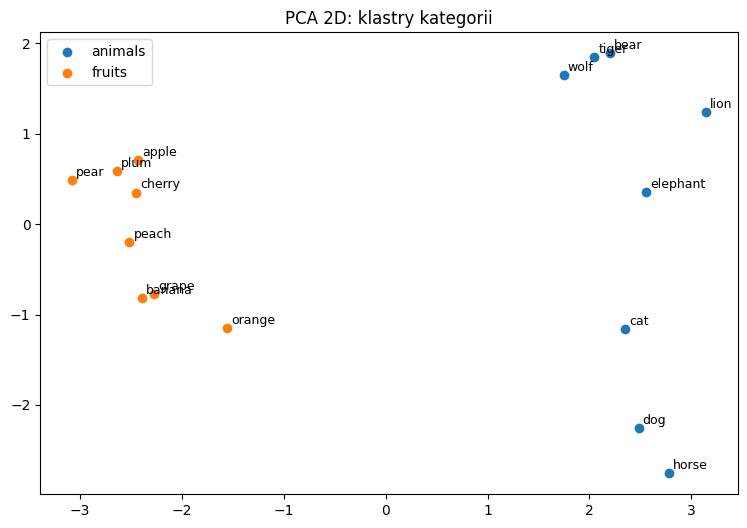

In [23]:
from sklearn.decomposition import PCA

def plot_groups(groups, title="PCA 2D: klastry kategorii"):
    words, labels = [], []
    for g, ws in groups.items():
        for w in ws:
            if w in glove:
                words.append(w); labels.append(g)
            else:
                print("Brak w słowniku:", w)
    X2 = PCA(n_components=2).fit_transform(np.array([glove[w] for w in words]))

    plt.figure(figsize=(9, 6))
    for g in groups:
        idx = [i for i, l in enumerate(labels) if l == g]
        plt.scatter(X2[idx, 0], X2[idx, 1], label=g)
        for i in idx:
            plt.annotate(words[i], (X2[i, 0], X2[i, 1]), fontsize=9, xytext=(3, 3), textcoords="offset points")
    plt.legend(); plt.title(title); plt.show()

plot_groups({
    "animals": ["dog", "cat", "horse", "lion", "tiger", "elephant", "bear", "wolf"],
    "fruits": ["banana", "orange", "pear", "grape", "peach", "cherry", "plum", "apple"],
})

### Zadanie 7
Zdefiniuj grupy (po 6–8 słów): `colors`, `animals`, `cities`, `countries`, `tech_brands`. Dodaj `paris` do miast, `france` do krajów,
a `apple` do `tech_brands`. Narysuj wykres funkcją `plot_groups` i odpowiedz:
1. Które grupy tworzą najbardziej zwarte klastry?
2. Gdzie leżą `cities` i `countries` względem siebie? Czy `paris` jest blisko `france`?
3. Gdzie wypadło `apple`? Dlaczego?

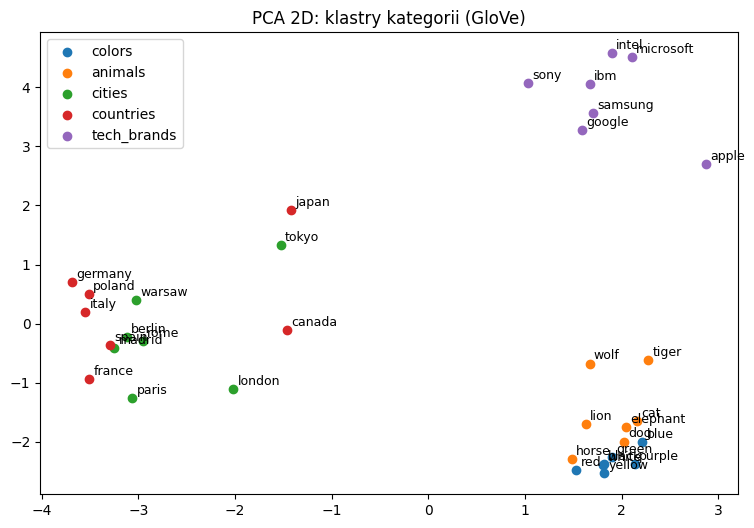

In [24]:
# TODO
groups_task7 = {
    "colors": ["red", "blue", "green", "yellow", "black", "white", "purple"],
    "animals": ["dog", "cat", "horse", "lion", "tiger", "elephant", "wolf"],
    "cities": ["paris", "berlin", "madrid", "rome", "london", "tokyo", "warsaw"],
    "countries": ["france", "germany", "spain", "italy", "poland", "japan", "canada"],
    "tech_brands": ["apple", "microsoft", "google", "ibm", "intel", "sony", "samsung"],
}

plot_groups(groups_task7, title="PCA 2D: klastry kategorii (GloVe)")

**Odpowiedzi:**
1. colors animals i tech brands
2. Grupy cities i countries zwykle leżą blisko siebie lub częściowo obok siebie, ponieważ stolice/miasta często występują w tych samych artykułach i kontekstach geograficznych co państwa, paris jest blisko france (i blisko innych dużych miast europejskich), ponieważ w korpusach typu Wikipedia / wiadomości konteksty związane z Francją i Paryżem silnie się przenikają.
3. apple trafia w pobliże grupy tech_brands, może też leżeć lekko na uboczu między technologią a owocami/żywnością jakby było, bo w korpusie wikipedi słowo apple jest wieloznaczne oznacza zarówno firmę technologiczną Apple, jak i owoc

*(miejsce na Twoje odpowiedzi)*

## 6. Ograniczenie: jedno słowo = jeden wektor

W word2vec i GloVe każde słowo ma **jeden** wektor, niezależnie od zdania:
- „I ate an **apple**” – owoc,
- „**Apple** released a new iPhone” – firma.

Oba zdania dostają ten sam wektor `apple`. Model nie wie, o które znaczenie chodzi.

In [25]:
for w in ["apple", "mouse", "python"]:
    print(f"{w:>7}:", [s for s, _ in glove.most_similar(w, topn=10)])

  apple: ['microsoft', 'ibm', 'intel', 'software', 'dell', 'pc', 'macintosh', 'iphone', 'ipod', 'hewlett']
  mouse: ['cat', 'rabbit', 'monkey', 'mice', 'rat', 'spider', 'bugs', 'dog', 'robot', 'clone']
 python: ['monty', 'php', 'perl', 'cleese', 'flipper', 'ruby', 'spamalot', 'javascript', 'reticulated', 'monkey']


Sąsiedzi pokazują, które znaczenie „wygrało” w danych (dla `apple` – firma, dla `mouse` – zwierzę), a pozostałe znaczenia są
zmieszane w tym samym wektorze (`python` – język programowania, Monty Python i wąż naraz).

**Jak to rozwiązuje GPT?** Na wejściu GPT też ma **statyczny** embedding tokenu (tablica 50 257 × 768). Ale potem wektor przechodzi
przez kolejne warstwy z **mechanizmem uwagi** (zajęcia 7), które mieszają go z wektorami innych tokenów w zdaniu.
Na wyjściu każdy token ma **embedding kontekstowy**: `apple` obok „iPhone” i `apple` obok „ate” dostają różne wektory.

### Zadanie 8
1. Znajdź dwa inne słowa wieloznaczne (np. `java`, `spring`, `bat`, `crane`, `bank`) i sprawdź ich sąsiadów. Które znaczenie dominuje?
2. Dlaczego dominuje właśnie to znaczenie?

In [26]:
# TODO
for w in ["java", "bank"]:
    neighbors = [s for s, _ in glove.most_similar(w, topn=10)]
    print(f"{w:>6}: {neighbors}")

  java: ['sumatra', 'surabaya', 'semarang', 'sulawesi', 'yogyakarta', 'bandung', 'mindanao', 'banten', 'borneo', 'luzon']
  bank: ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds', 'ubs', 'finance']


**Odpowiedzi:**
1. java: w korpusach typu Wikipedia / wiadomości zazwyczaj mocno dominuje znaczenie geograficzne (wyspa Jawa w Indonezji — w kontekście innych wysp/regionów Indonezji, np. sumatra, borneo, bali, jakarta), czasem z domieszką kawy lub języka programowania w dalszej kolejności. bank: w takich korpusach wyraźnie dominuje znaczenie instytucji finansowej / bankowości (np. banks, banking, credit, loan, financial, central), a rzadsze znaczenie „brzeg rzeki” (np. riverbank) bywa w mniejszości lub pojawia się głównie w złożeniach.
2. Ponieważ statyczny embedding (jeden wektor na słowo) odzwierciedla statystyczną częstość występowania poszczególnych znaczeń w korpusie treningowym (tu: Wikipedia + wiadomości).

*(miejsce na Twoje odpowiedzi)*

## 7. Podsumowanie

| | one-hot | Bag-of-Words | word2vec / GloVe | GPT (zajęcia 7–8) |
|---|---|---|---|---|
| Co opisuje wektor | słowo | zdanie | słowo | token **w kontekście** |
| Wymiar | rozmiar słownika (duży, rzadki) | rozmiar słownika | 50–300 (gęsty) | 768 w GPT-2 small |
| Modeluje podobieństwo słów | nie | tylko identyczne słowa | **tak** | **tak** |
| Uwzględnia kolejność słów | – | nie | nie | **tak** (embeddingi pozycji) |
| Zależy od kontekstu zdania | nie | – | nie | **tak** (mechanizm uwagi) |
| Skąd się bierze | z definicji | ze zliczeń | **uczony** – przewidywanie sąsiadów | **uczony** – przewidywanie następnego tokenu |

**Główna myśl:** dobre wektory słów powstają **z przewidywania kontekstu**. word2vec przewiduje sąsiadów i daje jeden wektor na słowo.
GPT przewiduje następny token, a dzięki uwadze daje wektor zależny od całego zdania.

**Pytania kontrolne:**
1. Dlaczego one-hot nie wystarcza jako reprezentacja słowa?
2. Co tracimy w reprezentacji Bag-of-Words?
3. Na jakim zadaniu uczy się word2vec (skip-gram) i dlaczego daje to sensowne wektory?
4. Co oznacza, że `king − man + woman ≈ queen`?
5. Jakiego problemu statycznych embeddingów nie rozwiązuje word2vec i jak rozwiązuje go GPT?

**Odpowiedzi:**
1. Brak informacji o znaczeniu i podobieństwie: każde słowo ma „jedynkę” na innej pozycji i same zera reszty — wektory dla pies i kot są tak samo od siebie „odległe” (ortogonalne) jak wektory dla pies i lodówka.
2. Kolejność słów i składnię: zdania o zupełnie innym znaczeniu z tymi samymi słowami (np. „dog bites man” vs „man bites dog”) dostają identyczny wektor.
Semantykę i synonimy: model traktuje każde słowo jako niezależną „szufladkę” — nie wie, że kot i kociak albo dobry i świetny oznaczają coś bliskiego.
Kontekst i zaprzeczenia: proste zliczanie słów łatwo gubi niuanse (np. „not good” nadal zawiera „good”).
3. dla danego słowa wejściowego (środkowego) model przewiduje słowa z jego okna kontekstowego (sąsiadujące słowa w tekście).
Dlaczego daje sensowne wektory: słowa, które pojawiają się w podobnych kontekstach, muszą umieć przewidywać podobne sąsiednie słowa — dlatego sieć „układa” ich wektory blisko siebie w przestrzeni (oraz wychwytuje powtarzalne relacje między parami słów).
4. Relacje mają kierunek w przestrzeni wektorowej: różnica wektorów woman - man reprezentuje pewne przesunięcie związane z płcią (w kontekście ról/osób).Dodając ten kierunek do wektora king, lądujemy w obszarze przestrzeni odpowiadającym „królowej” — czyli najbliżej wektora queen. To pokazuje, że embeddingi przechowują nie tylko same słowa, ale też regularne analogie / relacje między nimi.
5. Problem statycznych embeddingów: każde słowo dostaje jeden, stały wektor niezależnie od zdania — nie rozróżnia znaczeń słowa wieloznacznego (np. bank jako instytucja vs brzeg rzeki) ani nie uwzględnia bieżącego kontekstu (np. zaprzeczeń czy kolejności w zdaniu).
Jak rozwiązuje to GPT: GPT używa kontekstowych reprezentacji opartych na mechanizmie uwagi (self-attention) — ten sam token otrzymuje różny wektor w zależności od całego kontekstu, w którym występuje, dzięki czemu lepiej łapie wieloznaczność, składnię, negacje i zależności na dłuższym dystansie.

*(odpowiedz dla siebie – to dobre pytania przed kolejnymi zajęciami)*

---
# Zadania domowe

Zadania D1 i D2 są obowiązkowe, D3 i D4 – dla chętnych.

### D1. Uprzedzenia w embeddingach ⭐ (obowiązkowe)

**Motywacja:** embeddingi uczą się z tekstów pisanych przez ludzi – razem ze stereotypami. LLM-y dziedziczą ten problem.

1. Rozwiąż analogie `man : X :: woman : ?` dla zawodów: `doctor`, `programmer`, `engineer`, `boss`.
2. Policz „kierunek płci” `d = glove["he"] − glove["she"]`. Dla listy zawodów: `nurse, engineer, doctor, teacher, programmer, secretary,
   pilot, librarian, scientist, receptionist, surgeon, hairdresser, mechanic, dancer, manager, nanny` policz `cosine(glove[zawód], d)`
   i posortuj. Wartości dodatnie – zawód „bliżej he”, ujemne – „bliżej she”.
3. Zinterpretuj wyniki (3–5 zdań). Czy któryś wynik Cię zaskoczył? Jakie mogą być konsekwencje, jeśli taki model jest użyty np. do filtrowania CV?

In [33]:
# TODO: D1
import numpy as np

# 1. Analogie man : X :: woman : ?  -->  X - man + woman
professions_analogy = ["doctor", "programmer", "engineer", "boss"]

print("=== Analogie (X - man + woman) ===")
for x in professions_analogy:
    res = glove.most_similar(positive=[x, "woman"], negative=["man"], topn=3)
    clean = [s for s, _ in res]
    print(f"{x:>10}: {clean}")

# 2. Kierunek płci d = glove["he"] - glove["she"] i sortowanie zawodów
d = glove["he"] - glove["she"]

jobs = [
    "nurse", "engineer", "doctor", "teacher", "programmer", "secretary",
    "pilot", "librarian", "scientist", "receptionist", "surgeon",
    "hairdresser", "mechanic", "dancer", "manager", "nanny"
]

scores = [(job, cosine(glove[job], d)) for job in jobs]
scores_sorted = sorted(scores, key=lambda item: item[1], reverse=True)
print("\n=== Projekcja na kierunek d = he - she (malejąco) ===")
for job, val in scores_sorted:
    print(f"{job:>13}: {val:+.4f}")

=== Analogie (X - man + woman) ===
    doctor: ['nurse', 'physician', 'doctors']
programmer: ['educator', 'programmers', 'linguist']
  engineer: ['technician', 'educator', 'engineers']
      boss: ['bosses', 'girlfriend', 'boyfriend']

=== Projekcja na kierunek d = he - she (malejąco) ===
      manager: +0.2648
    secretary: +0.1656
     engineer: +0.1472
     mechanic: +0.1074
    scientist: +0.0681
   programmer: +0.0537
      surgeon: -0.0011
        pilot: -0.0039
       doctor: -0.0661
      teacher: -0.0919
    librarian: -0.1120
        nanny: -0.2635
 receptionist: -0.2768
  hairdresser: -0.2786
        nurse: -0.2952
       dancer: -0.3104


**Odpowiedzi:**
3. Wyniki wyraźnie pokazują, że wektory GloVe utrwalają historyczne i społeczne stereotypy obecne w korpusach treningowych: zawody techniczne i zarządcze (np. engineer, programmer, mechanic, pilot) przesuwają się w stronę dodatnią (he), podczas gdy zawody opiekuńcze, biurowe czy usługowe (np. nurse, nanny, secretary, receptionist, hairdresser) częściej lądują po stronie ujemnej (she). Szczególnie uderzające bywa to, gdy model zmienia sam zawód w analogii zamiast zachować jego rolę, albo gdy silnie wiąże konkretne stanowiska z jedną płcią. Jeśli taki embedding (albo model oparty na podobnych danych) zostanie użyty przy filtrowaniu CV czy dopasowywaniu kandydatów, może nieświadomie premiować lub dyskryminować osoby ze względu na płeć — np. poprzez słowa kojarzone z płcią w opisie doświadczenia, zainteresowań lub nazw ról. To z kolei prowadzi do automatyzacji dyskryminacji i utrwalania nierówności na rynku pracy.

*(miejsce na Twoje odpowiedzi)*

### D2. Wektor zdania ze średniej embeddingów ⭐⭐ (obowiązkowe)

**Motywacja:** najprostszy sposób, żeby dostać wektor zdania z embeddingów słów, to policzyć ich **średnią**.
Ten sam pomysł („mean pooling”) wykorzystamy na zajęciach 6 w klasyfikatorze tekstu.

1. Napisz funkcję `sentence_vector(s)`, która zwraca średnią wektorów GloVe słów zdania (pomiń słowa spoza słownika).
2. Dla par zdań policz podobieństwo cosinusowe **dwiema metodami**: BoW i średnia GloVe:
   - `"the cat sat on the mat"` vs `"a kitten rested on the rug"`
   - `"the cat sat on the mat"` vs `"the stock market fell today"`
   - `"dog bites man"` vs `"man bites dog"`
   - `"the movie was good"` vs `"the movie was not good"`
3. Porównaj wyniki. Co poprawiły embeddingi względem BoW? Jakich problemów nie rozwiązały?

In [34]:
# TODO: D2
def sentence_vector(s):
  vecs = [glove[w] for w in s.lower().split() if w in glove]
# Zabezpieczenie na wypadek zdania, w którym żadne słowo nie jest w słowniku
  if not vecs:
    return np.zeros(glove.vector_size, dtype=np.float32)

  return np.mean(vecs, axis=0)

pairs = [
    ("the cat sat on the mat", "a kitten rested on the rug"),
    ("the cat sat on the mat", "the stock market fell today"),
    ("dog bites man", "man bites dog"),
    ("the movie was good", "the movie was not good"),
]

for s1, s2 in pairs:
    # 1. BoW (wspólny słownik dla danej pary zdań)
    vocab = sorted(set((s1 + " " + s2).lower().split()))
    v1_bow = np.array([s1.lower().split().count(w) for w in vocab])
    v2_bow = np.array([s2.lower().split().count(w) for w in vocab])
    sim_bow = cosine(v1_bow, v2_bow)

    # 2. Średnia wektorów GloVe
    v1_glove = sentence_vector(s1)
    v2_glove = sentence_vector(s2)
    sim_glove = cosine(v1_glove, v2_glove)

    print(f"'{s1}'  <-->  '{s2}'")
    print(f"   BoW:   {sim_bow:.4f}   |   GloVe mean: {sim_glove:.4f}\n")

'the cat sat on the mat'  <-->  'a kitten rested on the rug'
   BoW:   0.4330   |   GloVe mean: 0.9215

'the cat sat on the mat'  <-->  'the stock market fell today'
   BoW:   0.3162   |   GloVe mean: 0.7321

'dog bites man'  <-->  'man bites dog'
   BoW:   1.0000   |   GloVe mean: 1.0000

'the movie was good'  <-->  'the movie was not good'
   BoW:   0.8944   |   GloVe mean: 0.9907



**Odpowiedzi:**
3. w parze "the cat sat on the mat" vs "a kitten rested on the rug" BoW widzi niemal same różne słowa, więc podobieństwo wychodzi niskie. Średnia z GloVe daje znacznie wyższe podobieństwo, bo wektory synonimów leżą blisko siebie.
Lepsze oddzielenie zupełnie różnych tematów. czego nie rozwiązały: Kolejność słów / składnia ("dog bites man" vs "man bites dog"), Zaprzeczenia ("the movie was good" vs "the movie was not good"): dodanie słowa "not" lekko przesuwa średnią wektorów, ale nie odwraca znaczenia całego zdania, Brak kontekstu zdaniowego
*(miejsce na Twoje odpowiedzi)*

### D3. Okno kontekstu a rodzaj podobieństwa ⭐⭐ (dla chętnych)

**Motywacja:** szerokość okna decyduje, *jakie* podobieństwo łapie model.

1. Wytrenuj na `text8` dwa modele word2vec: `window=2` i `window=10` (reszta parametrów jak w części 3.3).
2. Porównaj top-8 sąsiadów dla słów: `walk`, `dog`, `france`, `physics`, `blue`.
3. Który model daje sąsiadów „tej samej kategorii gramatycznej / tego samego typu” (np. inne czasowniki ruchu), a który „z tego samego tematu”
   (np. słowa występujące w tym samym artykule)? Dlaczego?
4. (Opcjonalnie) Sprawdź wpływ `vector_size=20` vs `vector_size=200`.

In [36]:
# TODO: D3
w2v_win2 = Word2Vec(text8, vector_size=100, window=2, min_count=5, sg=1, epochs=5, seed=0, workers=2)
w2v_win10 = Word2Vec(text8, vector_size=100, window=10, min_count=5, sg=1, epochs=5, seed=0, workers=2)

words_to_check = ["walk", "dog", "france", "physics", "blue"]
for w in words_to_check:
    print(f"{w:>9}:")
    print(f"  win2: {w2v_win2.wv.most_similar(w, topn=8)}")
    print(f"win10: {w2v_win10.wv.most_similar(w, topn=8)}\n")

     walk:
  win2: [('sit', 0.775508463382721), ('spot', 0.7718483209609985), ('bounce', 0.7681989073753357), ('ride', 0.7653034329414368), ('assemble', 0.7531905770301819), ('hook', 0.7519719004631042), ('pick', 0.7452113032341003), ('draw', 0.7441173195838928)]
win10: [('walks', 0.7004753351211548), ('throws', 0.6627292633056641), ('notch', 0.6591349244117737), ('walking', 0.6565593481063843), ('throw', 0.6549326777458191), ('walked', 0.6491595506668091), ('steal', 0.6474868655204773), ('climb', 0.6447185277938843)]

      dog:
  win2: [('doo', 0.7583925127983093), ('bonzo', 0.7439373135566711), ('cat', 0.742035448551178), ('purple', 0.724563479423523), ('sad', 0.7208168506622314), ('leopard', 0.7206685543060303), ('goat', 0.7181161046028137), ('pig', 0.7091202139854431)]
win10: [('hound', 0.8167967200279236), ('dogs', 0.7140249013900757), ('cat', 0.698654055595398), ('terrier', 0.6957290172576904), ('hounds', 0.6942271590232849), ('donkey', 0.6921900510787964), ('breed', 0.690986275

**Odpowiedzi:**
3. Węższe okno (window=2) daje częściej sąsiadów tej samej kategorii gramatycznej ponieważ najbliższe słowa tuż obok słowa docelowego silnie determinują jego składnię i bezpośrednią funkcję w zdaniu
Szersze okno (window=10) daje częściej sąsiadów z tego samego tematu / domeny ponieważ większy promień kontekstu łapie szersze powiązania tematyczne w całym fragmencie tekstu, a nie tylko bezpośrednie sąsiedztwo składniowe.

*(miejsce na Twoje odpowiedzi)*

### D4. Test analogii: GloVe vs własny word2vec ⭐⭐⭐ (dla chętnych)

**Motywacja:** jak porównać dwa modele embeddingów liczbowo? Standardem jest zbiór ok. 19 500 analogii Google (`questions-words.txt`),
który jest dołączony do biblioteki gensim.

1. Uruchom `evaluate_word_analogies` dla GloVe i dla modelu `w2v` z części 3.3.
2. Porównaj dokładność całkowitą i dokładność w poszczególnych kategoriach (np. `capital-common-countries`, `currency`, `gram8-plural`).
3. Który model jest lepszy i dlaczego? Które kategorie są najtrudniejsze?

In [38]:
# TODO: D4
from gensim.test.utils import datapath
questions = datapath("questions-words.txt")
def eval_analogies(kv, name="Model"):
    acc, sections = kv.evaluate_word_analogies(questions)
    print(f"=== {name} | Dokładność całkowita: {acc:.4f} ({acc*100:.2f}%) ===")

    # Wyciągamy wyniki per kategoria i sortujemy od najtrudniejszych (najniższa dokładność)
    per_cat = []
    for sec in sections:
        sec_name = sec.get("section", "unknown")
        ok = len(sec.get("correct", []))
        bad = len(sec.get("incorrect", []))
        total = ok + bad
        cat_acc = (ok / total) if total > 0 else 0.0
        per_cat.append((sec_name, cat_acc, ok, total))

    return acc, per_cat

glove_acc, glove_cats = eval_analogies(glove, "GloVe (wiki-gigaword-100)")
w2v_acc, w2v_cats     = eval_analogies(w2v.wv, "Word2Vec (część 3.3)")

# Porównanie wybranych kategorii + ogólne zestawienie
target_cats = ["capital-common-countries", "currency", "gram8-plural"]
glove_map = {name: (c_acc, ok, tot) for name, c_acc, ok, tot in glove_cats}
w2v_map   = {name: (c_acc, ok, tot) for name, c_acc, ok, tot in w2v_cats}

print("\n=== Wybrane kategorie ===")
for cat in target_cats:
    g_val, g_ok, g_tot = glove_map.get(cat, (0.0, 0, 0))
    w_val, w_ok, w_tot = w2v_map.get(cat, (0.0, 0, 0))
    print(f"{cat:<26} | GloVe: {g_val*100:5.1f}% ({g_ok}/{g_tot}) | W2V: {w_val*100:5.1f}% ({w_ok}/{w_tot})")

print("\n=== Najtrudniejsze kategorie (GloVe, rosnąco) ===")
for cat, c_acc, ok, tot in sorted(glove_cats, key=lambda x: x[1])[:5]:
    print(f"  {cat:<28}: {c_acc*100:5.1f}% ({ok}/{tot})")

print("\n=== Najtrudniejsze kategorie (W2V, rosnąco) ===")
for cat, c_acc, ok, tot in sorted(w2v_cats, key=lambda x: x[1])[:5]:
    print(f"  {cat:<28}: {c_acc*100:5.1f}% ({ok}/{tot})")

=== GloVe (wiki-gigaword-100) | Dokładność całkowita: 0.6330 (63.30%) ===
=== Word2Vec (część 3.3) | Dokładność całkowita: 0.1474 (14.74%) ===

=== Wybrane kategorie ===
capital-common-countries   | GloVe:  93.9% (475/506) | W2V:  19.9% (92/462)
currency                   | GloVe:  15.2% (123/808) | W2V:   4.4% (15/338)
gram8-plural               | GloVe:  72.0% (959/1332) | W2V:  14.8% (166/1122)

=== Najtrudniejsze kategorie (GloVe, rosnąco) ===
  currency                    :  15.2% (123/808)
  gram2-opposite              :  20.1% (163/812)
  gram1-adjective-to-adverb   :  24.4% (242/992)
  city-in-state               :  30.8% (760/2467)
  gram4-superlative           :  54.3% (609/1122)

=== Najtrudniejsze kategorie (W2V, rosnąco) ===
  gram1-adjective-to-adverb   :   3.7% (26/702)
  currency                    :   4.4% (15/338)
  gram2-opposite              :   6.1% (23/380)
  gram7-past-tense            :   7.2% (106/1482)
  capital-world               :   7.6% (132/1730)


**Odpowiedzi:**
Zazwyczaj wyraźnie lepszy okazuje się glove wytrenowany na około 6 mld słów z Wikipedii i wiadomości niż w2v trenowany na relatywnie niewielkim korpusie text8 (~17 mln słów). Większy korpus to bogatsze statystyki współwystępowania, więcej przykładów relacji geograficznych, walut czy form gramatycznych oraz mniej brakujących słów w słowniku (w mniejszym korpusie wiele pytań z questions-words.txt po prostu wypada lub ma słabsze wektory).
capital-common-countries i gram8-plural (liczba mnoga rzeczowników) są zazwyczaj znacznie łatwiejsze i osiągają wyższą celność, bo relacje kraj–stolica oraz regularne końcówki liczby mnogiej tworzą dość spójne przesunięcia w przestrzeni.
currency bywa trudniejsze od stolic, bo waluty i kraje mają bardziej zróżnicowane konteksty (wspólne waluty jak euro, nazwy lokalne itp.).

*(miejsce na Twoje odpowiedzi)*